In [1]:
# Step 1 — Improve preprocessing

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("../data/processed/credit_card_cleaned.csv")

x = df.drop(columns=["ID", "default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pay_cols = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

def add_features(x):
    x=x.copy()

    x["months_with_delay"] = (
        x[pay_cols] > 0
    ).sum(axis=1)

    x["max_delay"] = (
        x[pay_cols].clip(lower=0).max(axis=1)
    )

    return x

X_train = add_features(X_train)
X_test = add_features(X_test)


In [2]:
# Define categorical and numerical features

categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE"
]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numerical_features),
    ("cat", categorical_preprocessor, categorical_features)
])

# The repayment status codes are kept numeric in this iteration, but remember that their special negative 
# values are not ordinary delay durations.

In [3]:
# Step 2 — Train and compare two models
# We'll compare Logistic Regression with Random Forest using five-fold stratified cross-validation 
# on the training data.

# This is important because your test set should be reserved for the 
# final assessment rather than repeatedly used to select models.


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

comparison = pd.DataFrame(results)

display(comparison)


,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.762427,0.515842
1,Random Forest,0.781403,0.556659


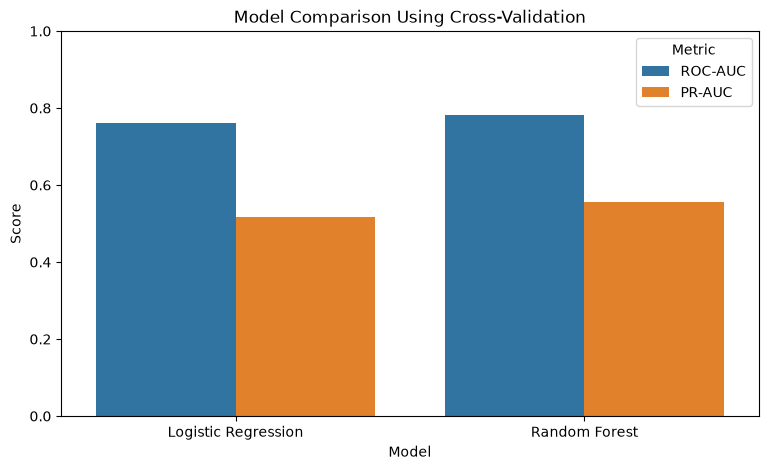

In [4]:
# Step 3 — Visualise the model comparison

import matplotlib.pyplot as plt
import seaborn as sns

comparison_long = comparison.melt(
    id_vars="Model",
    value_vars=["ROC-AUC", "PR-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Comparison Using Cross-Validation")
plt.ylim(0, 1)
plt.show()

In [5]:
# Step 4 — Select and train the best model

import joblib

best_model_name = comparison.loc[
    comparison["PR-AUC"].idxmax(),
    "Model"
]

print("Selected model:", best_model_name)

best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", models[best_model_name])
])

best_model.fit(X_train, y_train)

print("Best model fitted on full training data.")
joblib.dump(best_model, "best_model.pkl")
joblib.dump(X_test, "X_test.pkl")
joblib.dump(y_test, "y_test.pkl")

Selected model: Random Forest
Best model fitted on full training data.


['y_test.pkl']

              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.65      0.36      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.74      0.65      0.68      6000
weighted avg       0.80      0.82      0.79      6000

Test ROC-AUC: 0.773
Test Average Precision: 0.5509


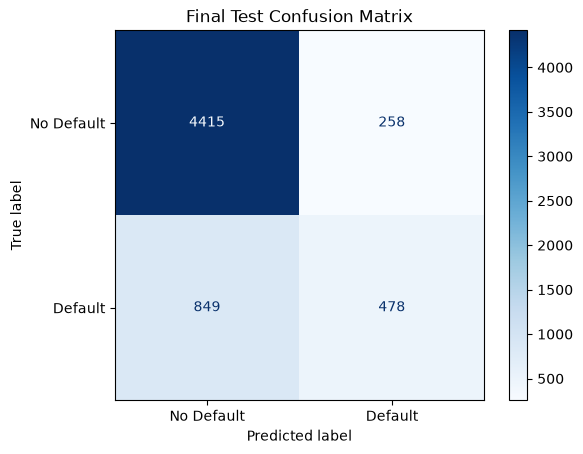

In [6]:
# Step 5 — Final held-out test evaluation
# Now evaluate the selected model once on the reserved test set

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

print(classification_report(y_test, y_pred))

print(
    "Test ROC-AUC:",
    round(roc_auc_score(y_test, y_prob), 4)
)

print(
    "Test Average Precision:",
    round(average_precision_score(y_test, y_prob), 4)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Final Test Confusion Matrix")
plt.show()


In [7]:
import joblib
from pathlib import Path

Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    best_model,
    "../models/best_credit_risk_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!
